In [ ]:

# ============================================================
# BERKELEY AI/ML CAPSTONE — DAY 3
# SaaS Observability / AIOps
# Statistical Baseline vs Isolation Forest
# ============================================================

from pathlib import Path
from urllib.request import urlretrieve
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix
)

SEED = 42
np.random.seed(SEED)

# ------------------------------------------------------------
# 1. Project directories
# ------------------------------------------------------------

root = Path.cwd().resolve()
if not (root / "data").exists():
    root = root.parent

raw_dir = root / "data/raw/nab"
out_dir = root / "data/processed/day3"
raw_dir.mkdir(parents=True, exist_ok=True)
out_dir.mkdir(parents=True, exist_ok=True)

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "numenta/NAB/master"
)

# Correct NAB source directories
SERIES = {
    "ec2_cpu_utilization_5f5533":
        "realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv",
    "ec2_cpu_utilization_24ae8d":
        "realAWSCloudwatch/ec2_cpu_utilization_24ae8d.csv",
    "ec2_cpu_utilization_53ea38":
        "realAWSCloudwatch/ec2_cpu_utilization_53ea38.csv",
    "ec2_request_latency_system_failure":
        "realKnownCause/ec2_request_latency_system_failure.csv",
    "cpu_utilization_asg_misconfiguration":
        "realKnownCause/cpu_utilization_asg_misconfiguration.csv"
}

labels_path = raw_dir / "anomaly_windows.json"

if not labels_path.exists():
    urlretrieve(
        BASE_URL + "/labels/combined_windows.json",
        labels_path
    )

with open(labels_path, encoding="utf-8") as f:
    annotations = json.load(f)

# ------------------------------------------------------------
# 2. Download and prepare each series
# ------------------------------------------------------------

def load_series(name, source):
    path = raw_dir / (name + ".csv")

    # Reuse the original Day 1 dataset if present
    if name == "ec2_cpu_utilization_5f5533":
        original = raw_dir / "cpu.csv"
        if original.exists() and not path.exists():
            path = original

    if not path.exists():
        print("Downloading:", source)
        urlretrieve(
            BASE_URL + "/data/" + source, path
        )

    df = pd.read_csv(path)

    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df["value"] = pd.to_numeric(
        df["value"], errors="coerce"
    )

    df = (
        df.dropna(subset=["timestamp", "value"])
          .drop_duplicates(subset=["timestamp"])
          .sort_values("timestamp")
          .reset_index(drop=True)
    )

    # Window membership is used for evaluation,
    # never as a model input.
    df["anomaly_label"] = 0

    if source not in annotations:
        raise KeyError(
            f"No NAB annotations found for {source}"
        )

    for start, end in annotations[source]:
        mask = df["timestamp"].between(
            pd.Timestamp(start),
            pd.Timestamp(end)
        )
        df.loc[mask, "anomaly_label"] = 1

    df["series"] = name

    # Strictly historical statistics:
    # shift(1) excludes the current value.
    previous = df["value"].shift(1)

    history = previous.rolling(
        window=12, min_periods=12
    )

    df["past_mean"] = history.mean()
    df["past_std"] = history.std()
    df["lag_1"] = previous
    df["lag_3"] = df["value"].shift(3)
    df["change"] = df["value"] - previous

    df["z_score"] = (
        (df["value"] - df["past_mean"]) /
        df["past_std"].clip(lower=1e-6)
    )

    df = df.replace(
        [np.inf, -np.inf], np.nan
    )

    features = [
        "value", "past_mean", "past_std",
        "lag_1", "lag_3", "change"
    ]

    df = df.dropna(
        subset=features + ["z_score"]
    ).reset_index(drop=True)

    return df, features


# ------------------------------------------------------------
# 3. Chronological model development
# ------------------------------------------------------------

results = []
predictions = []
models = {}

for name, source in SERIES.items():

    print("\n" + "=" * 65)
    print("DATASET:", name)
    print("=" * 65)

    df, feature_cols = load_series(name, source)

    n = len(df)

    train_end = int(n * 0.60)
    val_end = int(n * 0.80)

    train = df.iloc[:train_end].copy()
    validation = df.iloc[train_end:val_end].copy()
    test = df.iloc[val_end:].copy()

    if min(len(train), len(validation), len(test)) == 0:
        print("Insufficient observations; skipping.")
        continue

    print("Training:", len(train),
          "anomalies:", int(train.anomaly_label.sum()))
    print("Validation:", len(validation),
          "anomalies:", int(validation.anomaly_label.sum()))
    print("Testing:", len(test),
          "anomalies:", int(test.anomaly_label.sum()))

    # --------------------------------------------------------
    # Model A: Statistical baseline
    # --------------------------------------------------------

    # Historical z-score, threshold fixed in advance.
    # Do not tune using test labels.
    z_threshold = 3.0

    test["stat_prediction"] = (
        test["z_score"].abs() > z_threshold
    ).astype(int)

    # --------------------------------------------------------
    # Model B: Isolation Forest
    # --------------------------------------------------------

    scaler = RobustScaler()

    X_train = scaler.fit_transform(
        train[feature_cols]
    )

    X_val = scaler.transform(
        validation[feature_cols]
    )

    X_test = scaler.transform(
        test[feature_cols]
    )

    model = IsolationForest(
        n_estimators=200,
        max_samples="auto",
        contamination="auto",
        random_state=SEED,
        n_jobs=-1
    )

    model.fit(X_train)

    # Higher score = more anomalous
    train_scores = -model.score_samples(X_train)
    val_scores = -model.score_samples(X_val)
    test_scores = -model.score_samples(X_test)

    # Fixed 98th percentile of training scores.
    # Training labels are NOT used.
    threshold = float(
        np.quantile(train_scores, 0.98)
    )

    test["if_score"] = test_scores
    test["if_prediction"] = (
        test_scores > threshold
    ).astype(int)

    models[name] = {
        "scaler": scaler,
        "model": model,
        "threshold": threshold
    }

    # --------------------------------------------------------
    # 4. Evaluate held-out test period
    # --------------------------------------------------------

    y_true = test["anomaly_label"].to_numpy()

    for method, column in [
        ("Statistical Z-score", "stat_prediction"),
        ("Isolation Forest", "if_prediction")
    ]:

        y_pred = test[column].to_numpy()

        tn, fp, fn, tp = confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        ).ravel()

        # Recall and F1 cannot be interpreted
        # if the test period has no positive labels.
        has_positive = (tp + fn) > 0

        precision = precision_score(
            y_true, y_pred, zero_division=0
        )

        recall = (
            recall_score(y_true, y_pred, zero_division=0)
            if has_positive else np.nan
        )

        f1 = (
            f1_score(y_true, y_pred, zero_division=0)
            if has_positive else np.nan
        )

        false_positive_rate = (
            fp / (fp + tn)
            if (fp + tn) else np.nan
        )

        results.append({
            "series": name,
            "model": method,
            "test_rows": len(test),
            "test_anomalies": int(y_true.sum()),
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "false_positive_rate": false_positive_rate,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "TN": tn
        })

    predictions.append(test)

    # --------------------------------------------------------
    # 5. Plot predictions on the held-out test period
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(13, 4))

    ax.plot(
        test["timestamp"], test["value"],
        label="Observed metric", linewidth=1
    )

    actual = test[test["anomaly_label"] == 1]
    detected = test[test["if_prediction"] == 1]

    ax.scatter(
        actual["timestamp"], actual["value"],
        label="Inside NAB anomaly window",
        marker="o", s=14, alpha=0.4
    )

    ax.scatter(
        detected["timestamp"], detected["value"],
        label="Isolation Forest alert",
        marker="x", s=30
    )

    ax.set_title(f"Test Period: {name}")
    ax.set_xlabel("Time")
    ax.set_ylabel("Metric value")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 6. Model comparison
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

if results_df.empty:
    raise RuntimeError("No datasets were successfully evaluated.")

print("\n" + "=" * 65)
print("DAY 3 MODEL COMPARISON")
print("=" * 65)

display(results_df.round(4))

# Aggregate confusion counts across held-out periods.
# These are micro-averaged pointwise metrics.
summary_rows = []

for method, group in results_df.groupby("model"):

    tp = int(group["TP"].sum())
    fp = int(group["FP"].sum())
    fn = int(group["FN"].sum())
    tn = int(group["TN"].sum())

    summary_rows.append({
        "model": method,
        "TP": tp, "FP": fp,
        "FN": fn, "TN": tn,
        "precision": tp / (tp + fp)
            if tp + fp else np.nan,
        "recall": tp / (tp + fn)
            if tp + fn else np.nan,
        "f1": 2 * tp / (2 * tp + fp + fn)
            if 2 * tp + fp + fn else np.nan,
        "false_positive_rate": fp / (fp + tn)
            if fp + tn else np.nan
    })

summary_df = pd.DataFrame(summary_rows)

print("\nAGGREGATE HELD-OUT PERFORMANCE")
display(summary_df.round(4))

# ------------------------------------------------------------
# 7. Save output for the final report
# ------------------------------------------------------------

results_df.to_csv(
    out_dir / "per_series_comparison.csv",
    index=False
)

summary_df.to_csv(
    out_dir / "model_comparison.csv",
    index=False
)

pd.concat(predictions, ignore_index=True).to_csv(
    out_dir / "test_predictions.csv",
    index=False
)

# ------------------------------------------------------------
# 8. Evaluation limitations
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("EVALUATION NOTES")
print("=" * 65)

for name in SERIES:
    sub = results_df[results_df.series == name]

    if not sub.empty and sub.iloc[0].test_anomalies == 0:
        print(
            f"WARNING: {name} has zero labeled test "
            "anomalies. Its recall/F1 are undefined."
        )

print(
    "\nResults are pointwise comparisons, "
    "NOT official NAB benchmark scores."
)
print(
    "NAB anomaly windows represent allowable "
    "temporal detection intervals, not verified "
    "incident duration or precise root-cause timestamps."
)
print(
    "Each time series was modeled independently. "
    "Validation observations were reserved and "
    "test labels were not used for model fitting."
)
print(
    "Thresholds were fixed without inspecting "
    "held-out test labels."
)

print("\nSaved outputs to:", out_dir)
print("\nDAY 3 COMPLETE")



DATASET: ec2_cpu_utilization_5f5533
Training: 2412 anomalies: 201
Validation: 804 anomalies: 201
Testing: 804 anomalies: 0


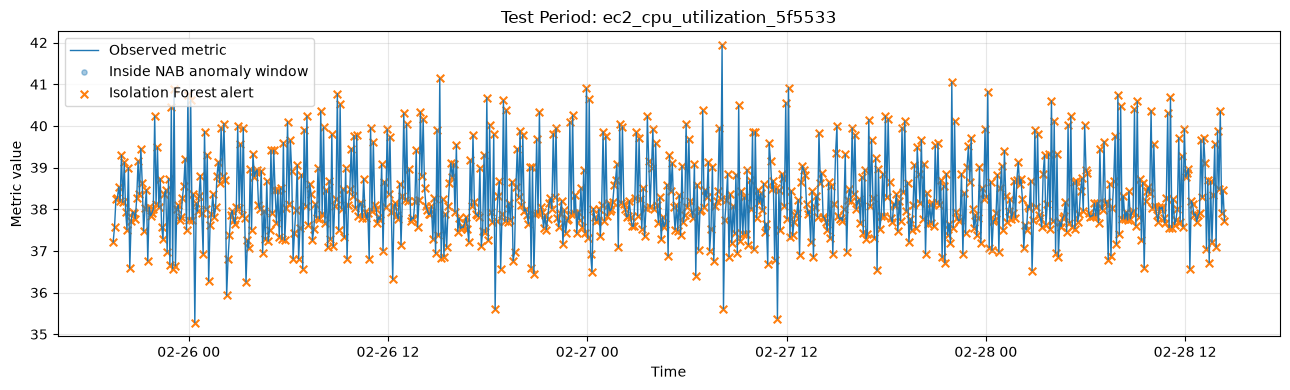


DATASET: ec2_cpu_utilization_24ae8d
Training: 2412 anomalies: 0
Validation: 804 anomalies: 0
Testing: 804 anomalies: 402


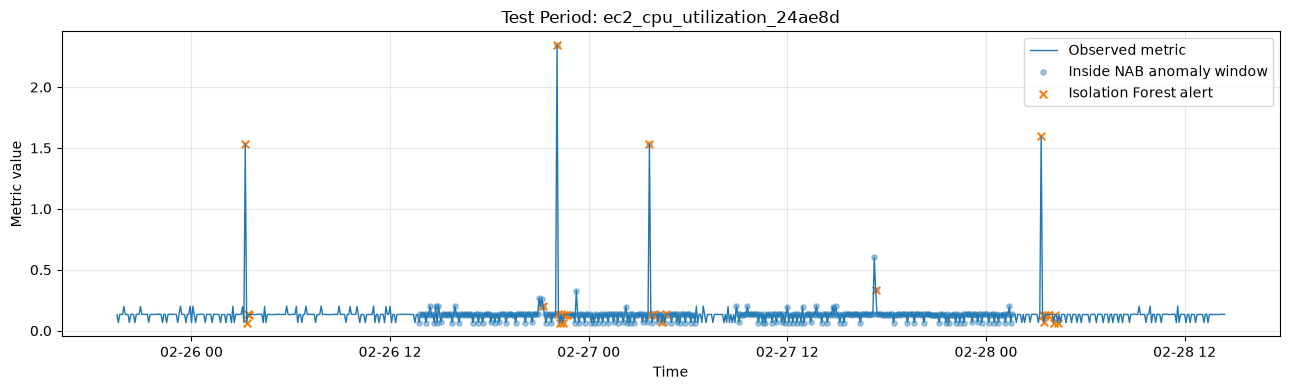


DATASET: ec2_cpu_utilization_53ea38
Training: 2412 anomalies: 201
Validation: 804 anomalies: 201
Testing: 804 anomalies: 0


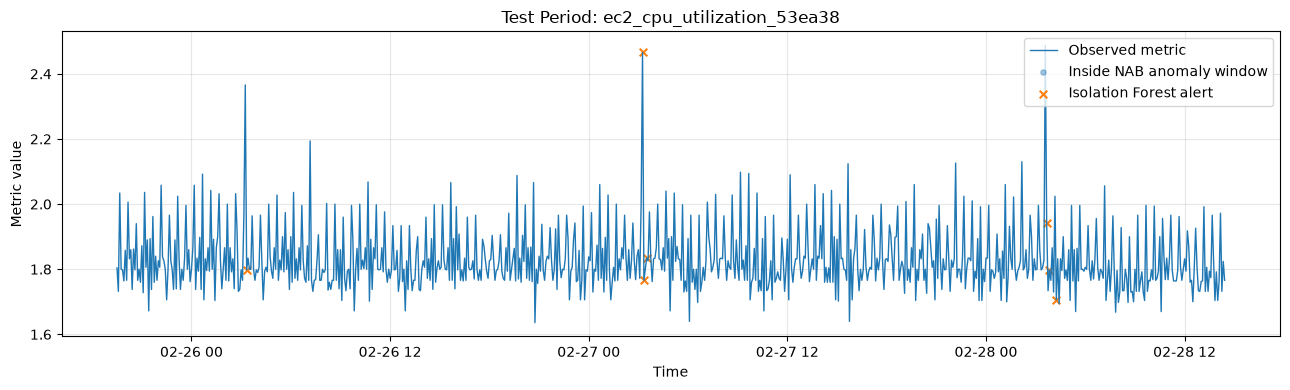


DATASET: ec2_request_latency_system_failure
Training: 2405 anomalies: 135
Validation: 802 anomalies: 0
Testing: 802 anomalies: 211


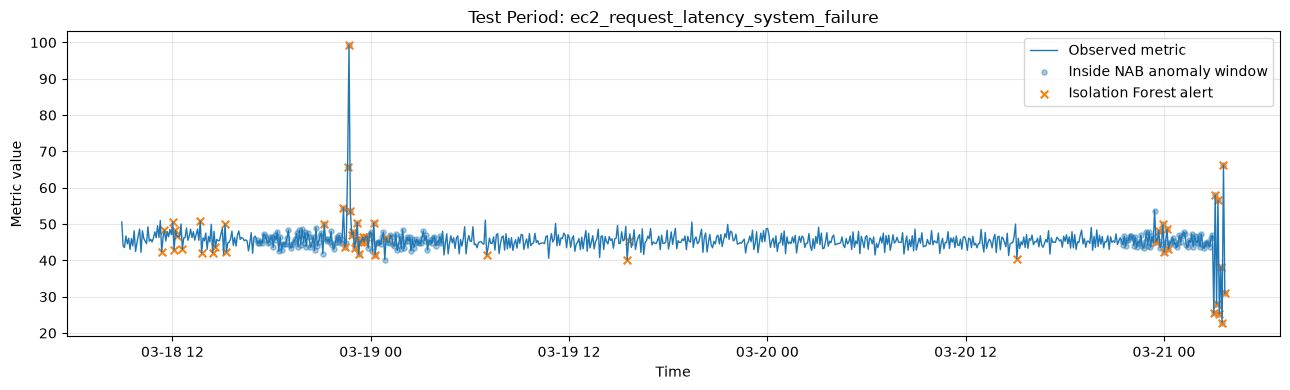


DATASET: cpu_utilization_asg_misconfiguration
Training: 10822 anomalies: 0
Validation: 3608 anomalies: 0
Testing: 3608 anomalies: 1499


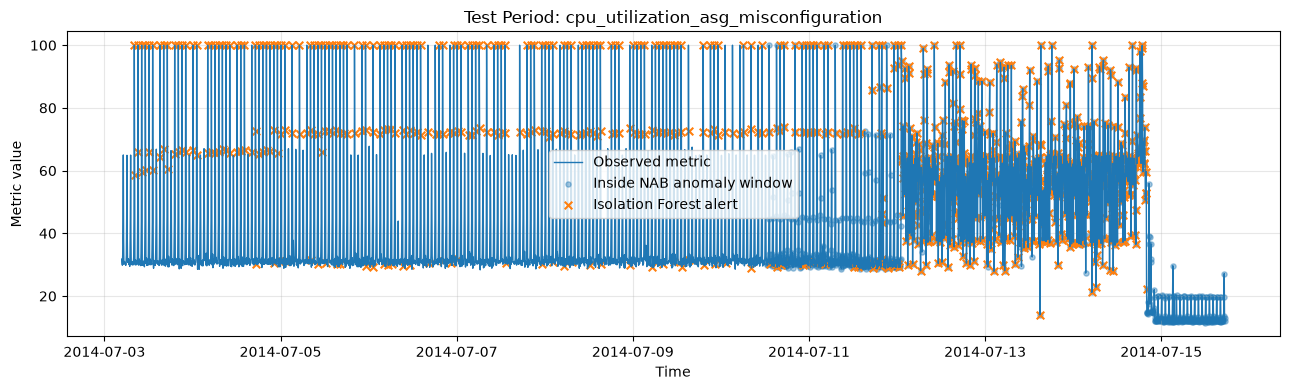


DAY 3 MODEL COMPARISON


,series,model,test_rows,test_anomalies,precision,recall,f1,false_positive_rate,TP,FP,FN,TN
0,ec2_cpu_utilization_5f5533,Statistical Z-score,804,0,0.0000,NaN,NaN,0.0062,0,5,0,799
1,ec2_cpu_utilization_5f5533,Isolation Forest,804,0,0.0000,NaN,NaN,1.0000,0,804,0,0
2,ec2_cpu_utilization_24ae8d,Statistical Z-score,804,402,0.5333,0.0398,0.0741,0.0348,16,14,386,388
3,ec2_cpu_utilization_24ae8d,Isolation Forest,804,402,0.5385,0.0348,0.0654,0.0299,14,12,388,390
4,ec2_cpu_utilization_53ea38,Statistical Z-score,804,0,0.0000,NaN,NaN,0.0149,0,12,0,792
5,ec2_cpu_utilization_53ea38,Isolation Forest,804,0,0.0000,NaN,NaN,0.0087,0,7,0,797
6,ec2_request_latency_system_failure,Statistical Z-score,802,211,0.3333,0.0237,0.0442,0.0169,5,10,206,581
7,ec2_request_latency_system_failure,Isolation Forest,802,211,0.6731,0.1659,0.2662,0.0288,35,17,176,574
8,cpu_utilization_asg_misconfiguration,Statistical Z-score,3608,1499,0.4366,0.0207,0.0395,0.0190,31,40,1468,2069
9,cpu_utilization_asg_misconfiguration,Isolation Forest,3608,1499,0.7475,0.5530,0.6357,0.1328,829,280,670,1829



AGGREGATE HELD-OUT PERFORMANCE


,model,TP,FP,FN,TN,precision,recall,f1,false_positive_rate
0,Isolation Forest,878,1120,1234,3590,0.4394,0.4157,0.4273,0.2378
1,Statistical Z-score,52,81,2060,4629,0.3910,0.0246,0.0463,0.0172



EVALUATION NOTES

Results are pointwise comparisons, NOT official NAB benchmark scores.
NAB anomaly windows represent allowable temporal detection intervals, not verified incident duration or precise root-cause timestamps.
Each time series was modeled independently. Validation observations were reserved and test labels were not used for model fitting.
Thresholds were fixed without inspecting held-out test labels.

Saved outputs to: C:\Users\rvmkr\saas-aiops-observability\data\processed\day3

DAY 3 COMPLETE


In [1]:
# ============================================================
# BERKELEY AI/ML CAPSTONE — DAY 3
# SaaS Observability / AIOps
# Statistical Baseline vs Isolation Forest
# ============================================================

from pathlib import Path
from urllib.request import urlretrieve
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix
)

SEED = 42
np.random.seed(SEED)

# ------------------------------------------------------------
# 1. Project directories
# ------------------------------------------------------------

root = Path.cwd().resolve()
if not (root / "data").exists():
    root = root.parent

raw_dir = root / "data/raw/nab"
out_dir = root / "data/processed/day3"
raw_dir.mkdir(parents=True, exist_ok=True)
out_dir.mkdir(parents=True, exist_ok=True)

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "numenta/NAB/master"
)

# Correct NAB source directories
SERIES = {
    "ec2_cpu_utilization_5f5533":
        "realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv",
    "ec2_cpu_utilization_24ae8d":
        "realAWSCloudwatch/ec2_cpu_utilization_24ae8d.csv",
    "ec2_cpu_utilization_53ea38":
        "realAWSCloudwatch/ec2_cpu_utilization_53ea38.csv",
    "ec2_request_latency_system_failure":
        "realKnownCause/ec2_request_latency_system_failure.csv",
    "cpu_utilization_asg_misconfiguration":
        "realKnownCause/cpu_utilization_asg_misconfiguration.csv"
}

labels_path = raw_dir / "anomaly_windows.json"

if not labels_path.exists():
    urlretrieve(
        BASE_URL + "/labels/combined_windows.json",
        labels_path
    )

with open(labels_path, encoding="utf-8") as f:
    annotations = json.load(f)

# ------------------------------------------------------------
# 2. Download and prepare each series
# ------------------------------------------------------------

def load_series(name, source):
    path = raw_dir / (name + ".csv")

    # Reuse the original Day 1 dataset if present
    if name == "ec2_cpu_utilization_5f5533":
        original = raw_dir / "cpu.csv"
        if original.exists() and not path.exists():
            path = original

    if not path.exists():
        print("Downloading:", source)
        urlretrieve(
            BASE_URL + "/data/" + source, path
        )

    df = pd.read_csv(path)

    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df["value"] = pd.to_numeric(
        df["value"], errors="coerce"
    )

    df = (
        df.dropna(subset=["timestamp", "value"])
          .drop_duplicates(subset=["timestamp"])
          .sort_values("timestamp")
          .reset_index(drop=True)
    )

    # Window membership is used for evaluation,
    # never as a model input.
    df["anomaly_label"] = 0

    if source not in annotations:
        raise KeyError(
            f"No NAB annotations found for {source}"
        )

    for start, end in annotations[source]:
        mask = df["timestamp"].between(
            pd.Timestamp(start),
            pd.Timestamp(end)
        )
        df.loc[mask, "anomaly_label"] = 1

    df["series"] = name

    # Strictly historical statistics:
    # shift(1) excludes the current value.
    previous = df["value"].shift(1)

    history = previous.rolling(
        window=12, min_periods=12
    )

    df["past_mean"] = history.mean()
    df["past_std"] = history.std()
    df["lag_1"] = previous
    df["lag_3"] = df["value"].shift(3)
    df["change"] = df["value"] - previous

    df["z_score"] = (
        (df["value"] - df["past_mean"]) /
        df["past_std"].clip(lower=1e-6)
    )

    df = df.replace(
        [np.inf, -np.inf], np.nan
    )

    features = [
        "value", "past_mean", "past_std",
        "lag_1", "lag_3", "change"
    ]

    df = df.dropna(
        subset=features + ["z_score"]
    ).reset_index(drop=True)

    return df, features


# ------------------------------------------------------------
# 3. Chronological model development
# ------------------------------------------------------------

results = []
predictions = []
models = {}

for name, source in SERIES.items():

    print("\n" + "=" * 65)
    print("DATASET:", name)
    print("=" * 65)

    df, feature_cols = load_series(name, source)

    n = len(df)

    train_end = int(n * 0.60)
    val_end = int(n * 0.80)

    train = df.iloc[:train_end].copy()
    validation = df.iloc[train_end:val_end].copy()
    test = df.iloc[val_end:].copy()

    if min(len(train), len(validation), len(test)) == 0:
        print("Insufficient observations; skipping.")
        continue

    print("Training:", len(train),
          "anomalies:", int(train.anomaly_label.sum()))
    print("Validation:", len(validation),
          "anomalies:", int(validation.anomaly_label.sum()))
    print("Testing:", len(test),
          "anomalies:", int(test.anomaly_label.sum()))

    # --------------------------------------------------------
    # Model A: Statistical baseline
    # --------------------------------------------------------

    # Historical z-score, threshold fixed in advance.
    # Do not tune using test labels.
    z_threshold = 3.0

    test["stat_prediction"] = (
        test["z_score"].abs() > z_threshold
    ).astype(int)

    # --------------------------------------------------------
    # Model B: Isolation Forest
    # --------------------------------------------------------

    scaler = RobustScaler()

    X_train = scaler.fit_transform(
        train[feature_cols]
    )

    X_val = scaler.transform(
        validation[feature_cols]
    )

    X_test = scaler.transform(
        test[feature_cols]
    )

    model = IsolationForest(
        n_estimators=200,
        max_samples="auto",
        contamination="auto",
        random_state=SEED,
        n_jobs=-1
    )

    model.fit(X_train)

    # Higher score = more anomalous
    train_scores = -model.score_samples(X_train)
    val_scores = -model.score_samples(X_val)
    test_scores = -model.score_samples(X_test)

    # Fixed 98th percentile of training scores.
    # Training labels are NOT used.
    threshold = float(
        np.quantile(train_scores, 0.98)
    )

    test["if_score"] = test_scores
    test["if_prediction"] = (
        test_scores > threshold
    ).astype(int)

    models[name] = {
        "scaler": scaler,
        "model": model,
        "threshold": threshold
    }

    # --------------------------------------------------------
    # 4. Evaluate held-out test period
    # --------------------------------------------------------

    y_true = test["anomaly_label"].to_numpy()

    for method, column in [
        ("Statistical Z-score", "stat_prediction"),
        ("Isolation Forest", "if_prediction")
    ]:

        y_pred = test[column].to_numpy()

        tn, fp, fn, tp = confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        ).ravel()

        # Recall and F1 cannot be interpreted
        # if the test period has no positive labels.
        has_positive = (tp + fn) > 0

        precision = precision_score(
            y_true, y_pred, zero_division=0
        )

        recall = (
            recall_score(y_true, y_pred, zero_division=0)
            if has_positive else np.nan
        )

        f1 = (
            f1_score(y_true, y_pred, zero_division=0)
            if has_positive else np.nan
        )

        false_positive_rate = (
            fp / (fp + tn)
            if (fp + tn) else np.nan
        )

        results.append({
            "series": name,
            "model": method,
            "test_rows": len(test),
            "test_anomalies": int(y_true.sum()),
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "false_positive_rate": false_positive_rate,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "TN": tn
        })

    predictions.append(test)

    # --------------------------------------------------------
    # 5. Plot predictions on the held-out test period
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(13, 4))

    ax.plot(
        test["timestamp"], test["value"],
        label="Observed metric", linewidth=1
    )

    actual = test[test["anomaly_label"] == 1]
    detected = test[test["if_prediction"] == 1]

    ax.scatter(
        actual["timestamp"], actual["value"],
        label="Inside NAB anomaly window",
        marker="o", s=14, alpha=0.4
    )

    ax.scatter(
        detected["timestamp"], detected["value"],
        label="Isolation Forest alert",
        marker="x", s=30
    )

    ax.set_title(f"Test Period: {name}")
    ax.set_xlabel("Time")
    ax.set_ylabel("Metric value")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 6. Model comparison
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

if results_df.empty:
    raise RuntimeError("No datasets were successfully evaluated.")

print("\n" + "=" * 65)
print("DAY 3 MODEL COMPARISON")
print("=" * 65)

display(results_df.round(4))

# Aggregate confusion counts across held-out periods.
# These are micro-averaged pointwise metrics.
summary_rows = []

for method, group in results_df.groupby("model"):

    tp = int(group["TP"].sum())
    fp = int(group["FP"].sum())
    fn = int(group["FN"].sum())
    tn = int(group["TN"].sum())

    summary_rows.append({
        "model": method,
        "TP": tp, "FP": fp,
        "FN": fn, "TN": tn,
        "precision": tp / (tp + fp)
            if tp + fp else np.nan,
        "recall": tp / (tp + fn)
            if tp + fn else np.nan,
        "f1": 2 * tp / (2 * tp + fp + fn)
            if 2 * tp + fp + fn else np.nan,
        "false_positive_rate": fp / (fp + tn)
            if fp + tn else np.nan
    })

summary_df = pd.DataFrame(summary_rows)

print("\nAGGREGATE HELD-OUT PERFORMANCE")
display(summary_df.round(4))

# ------------------------------------------------------------
# 7. Save output for the final report
# ------------------------------------------------------------

results_df.to_csv(
    out_dir / "per_series_comparison.csv",
    index=False
)

summary_df.to_csv(
    out_dir / "model_comparison.csv",
    index=False
)

pd.concat(predictions, ignore_index=True).to_csv(
    out_dir / "test_predictions.csv",
    index=False
)

# ------------------------------------------------------------
# 8. Evaluation limitations
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("EVALUATION NOTES")
print("=" * 65)

for name in SERIES:
    sub = results_df[results_df.series == name]

    if not sub.empty and sub.iloc[0].test_anomalies == 0:
        print(
            f"WARNING: {name} has zero labeled test "
            "anomalies. Its recall/F1 are undefined."
        )

print(
    "\nResults are pointwise comparisons, "
    "NOT official NAB benchmark scores."
)
print(
    "NAB anomaly windows represent allowable "
    "temporal detection intervals, not verified "
    "incident duration or precise root-cause timestamps."
)
print(
    "Each time series was modeled independently. "
    "Validation observations were reserved and "
    "test labels were not used for model fitting."
)
print(
    "Thresholds were fixed without inspecting "
    "held-out test labels."
)

print("\nSaved outputs to:", out_dir)
print("\nDAY 3 COMPLETE")

In [6]:
# Independent verification — Berkeley AIOps Capstone
from pathlib import Path
import pandas as pd
import numpy as np
import json
from sklearn.metrics import confusion_matrix

root = Path(r"C:\Users\rvmkr\saas-aiops-observability")
data_dir = root / "data/raw/nab"
result_dir = root / "data/processed/day3"

with open(data_dir / "anomaly_windows.json", encoding="utf-8") as f:
    windows = json.load(f)

sources = {
    "ec2_cpu_utilization_5f5533":
        "realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv",
    "ec2_cpu_utilization_24ae8d":
        "realAWSCloudwatch/ec2_cpu_utilization_24ae8d.csv",
    "ec2_cpu_utilization_53ea38":
        "realAWSCloudwatch/ec2_cpu_utilization_53ea38.csv",
    "ec2_request_latency_system_failure":
        "realKnownCause/ec2_request_latency_system_failure.csv",
    "cpu_utilization_asg_misconfiguration":
        "realKnownCause/cpu_utilization_asg_misconfiguration.csv"
}

pred = pd.read_csv(
    result_dir / "test_predictions.csv",
    parse_dates=["timestamp"]
)

reported = pd.read_csv(
    result_dir / "per_series_comparison.csv"
)

checks = []
recalculated = []

for name, source in sources.items():

    filename = (
        "cpu.csv" if name == "ec2_cpu_utilization_5f5533"
        else name + ".csv"
    )

    raw = pd.read_csv(
        data_dir / filename,
        parse_dates=["timestamp"]
    )

    raw = (
        raw.dropna(subset=["timestamp", "value"])
        .drop_duplicates(subset=["timestamp"])
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    actual = pred[pred["series"] == name].copy()
    actual = actual.sort_values("timestamp")

    # Rebuild annotations independently
    expected = np.zeros(len(actual), dtype=int)

    for start, end in windows[source]:
        mask = actual["timestamp"].between(
            pd.Timestamp(start),
            pd.Timestamp(end)
        )
        expected[mask.to_numpy()] = 1

    labels_match = np.array_equal(
        expected,
        actual["anomaly_label"].to_numpy()
    )

    # Verify predictions correspond to raw observations
    source_rows = raw.set_index("timestamp")["value"]
    matched_values = actual["timestamp"].map(source_rows)

    values_match = bool(np.allclose(
        matched_values.to_numpy(dtype=float),
        actual["value"].to_numpy(dtype=float),
        equal_nan=False
    ))

    chronological = bool(
        actual["timestamp"].is_monotonic_increasing
        and not actual["timestamp"].duplicated().any()
    )

    # Verify that test data starts after the
    # first 80% of feature-complete observations
    feature_ready = raw.copy()
    feature_ready["previous"] = feature_ready["value"].shift(1)
    feature_ready["past_mean"] = (
        feature_ready["previous"].rolling(12, min_periods=12).mean()
    )
    feature_ready["past_std"] = (
        feature_ready["previous"].rolling(12, min_periods=12).std()
    )
    feature_ready["lag_3"] = feature_ready["value"].shift(3)
    feature_ready["change"] = (
        feature_ready["value"] - feature_ready["previous"]
    )
    feature_ready["z_score"] = (
        (feature_ready["value"] - feature_ready["past_mean"]) /
        feature_ready["past_std"].clip(lower=1e-6)
    )

    feature_ready = feature_ready.replace(
        [np.inf, -np.inf], np.nan
    ).dropna(subset=[
        "value", "previous", "past_mean", "past_std",
        "lag_3", "change", "z_score"
    ]).reset_index(drop=True)

    test_start = int(len(feature_ready) * 0.80)
    expected_test_times = feature_ready.iloc[test_start:]["timestamp"]

    split_matches = np.array_equal(
        actual["timestamp"].to_numpy(),
        expected_test_times.to_numpy()
    )

    checks.append({
        "series": name,
        "labels_match": labels_match,
        "raw_values_match": values_match,
        "chronological": chronological,
        "split_matches": split_matches
    })

    for model_name, col in [
        ("Statistical Z-score", "stat_prediction"),
        ("Isolation Forest", "if_prediction")
    ]:
        y = expected
        p = actual[col].to_numpy(dtype=int)

        tn, fp, fn, tp = confusion_matrix(
            y, p, labels=[0, 1]
        ).ravel()

        saved = reported[
            (reported["series"] == name) &
            (reported["model"] == model_name)
        ]

        counts_match = (
            len(saved) == 1
            and int(saved.iloc[0]["TP"]) == tp
            and int(saved.iloc[0]["FP"]) == fp
            and int(saved.iloc[0]["FN"]) == fn
            and int(saved.iloc[0]["TN"]) == tn
        )

        recalculated.append({
            "series": name,
            "model": model_name,
            "TP": tp, "FP": fp,
            "FN": fn, "TN": tn,
            "saved_counts_match": counts_match
        })

print("DATA INTEGRITY CHECKS")
display(pd.DataFrame(checks))

print("\nINDEPENDENT CONFUSION MATRIX CHECKS")
display(pd.DataFrame(recalculated))

all_data_ok = bool(
    pd.DataFrame(checks).iloc[:, 1:].all().all()
)
all_counts_ok = bool(
    pd.DataFrame(recalculated)["saved_counts_match"].all()
)

print("\nDATA CHECKS:", "PASS" if all_data_ok else "REVIEW")
print("METRIC COUNTS:", "PASS" if all_counts_ok else "REVIEW")

print(
    "\nNote: These checks verify local integrity and "
    "reproducibility, not remote source authenticity "
    "or freedom from model-selection bias."
)


DATA INTEGRITY CHECKS


,series,labels_match,raw_values_match,chronological,split_matches
0,ec2_cpu_utilization_5f5533,True,True,True,True
1,ec2_cpu_utilization_24ae8d,True,True,True,True
2,ec2_cpu_utilization_53ea38,True,True,True,True
3,ec2_request_latency_system_failure,True,True,True,True
4,cpu_utilization_asg_misconfiguration,True,True,True,True



INDEPENDENT CONFUSION MATRIX CHECKS


,series,model,TP,FP,FN,TN,saved_counts_match
0,ec2_cpu_utilization_5f5533,Statistical Z-score,0,5,0,799,True
1,ec2_cpu_utilization_5f5533,Isolation Forest,0,804,0,0,True
2,ec2_cpu_utilization_24ae8d,Statistical Z-score,16,14,386,388,True
3,ec2_cpu_utilization_24ae8d,Isolation Forest,14,12,388,390,True
4,ec2_cpu_utilization_53ea38,Statistical Z-score,0,12,0,792,True
5,ec2_cpu_utilization_53ea38,Isolation Forest,0,7,0,797,True
6,ec2_request_latency_system_failure,Statistical Z-score,5,10,206,581,True
7,ec2_request_latency_system_failure,Isolation Forest,35,17,176,574,True
8,cpu_utilization_asg_misconfiguration,Statistical Z-score,31,40,1468,2069,True
9,cpu_utilization_asg_misconfiguration,Isolation Forest,829,280,670,1829,True



DATA CHECKS: PASS
METRIC COUNTS: PASS

Note: These checks verify local integrity and reproducibility, not remote source authenticity or freedom from model-selection bias.


In [7]:

# Day 4 — Diagnose Isolation Forest failure

import pandas as pd
import numpy as np
from pathlib import Path

root = Path(r"C:\Users\rvmkr\saas-aiops-observability")

pred = pd.read_csv(
    root / "data/processed/day3/test_predictions.csv"
)

series = "ec2_cpu_utilization_5f5533"
test = pred[pred["series"] == series].copy()

print("TEST DATA DISTRIBUTION")
print(test[["value", "past_mean", "past_std",
            "change", "if_score"]].describe())

print("\nISOLATION FOREST ALERT RATE")
print(test["if_prediction"].value_counts())

print("\nMODEL SCORE DISTRIBUTION")
print(test["if_score"].quantile(
    [0, 0.05, 0.25, 0.5, 0.75, 0.95, 1.0]
))

# Rebuild the chronological feature table
raw = pd.read_csv(
    root / "data/raw/nab/cpu.csv"
).sort_values("timestamp").reset_index(drop=True)

raw["previous"] = raw["value"].shift(1)
raw["past_mean"] = raw["previous"].rolling(12).mean()
raw["past_std"] = raw["previous"].rolling(12).std()
raw["change"] = raw["value"] - raw["previous"]

raw = raw.dropna().reset_index(drop=True)

cutoff = int(len(raw) * 0.60)

train = raw.iloc[:cutoff]

print("\nTRAIN VS TEST FEATURES")

for col in ["value", "past_mean", "past_std", "change"]:
    print(
        col,
        "| Train mean:", round(train[col].mean(), 4),
        "| Test mean:", round(test[col].mean(), 4),
        "| Train std:", round(train[col].std(), 4),
        "| Test std:", round(test[col].std(), 4)
    )


TEST DATA DISTRIBUTION
            value   past_mean    past_std      change    if_score
count  804.000000  804.000000  804.000000  804.000000  804.000000
mean    38.269776   38.268976    0.985701   -0.001199    0.627089
std      0.976196    0.140276    0.209260    1.545145    0.008600
min     35.278000   37.860667    0.471373   -6.326000    0.592849
25%     37.699500   38.173917    0.839923   -1.135500    0.621983
50%     38.062000   38.260000    0.949544    0.056000    0.630121
75%     38.772500   38.359208    1.122051    1.106500    0.634169
max     41.936000   38.649167    1.627532    4.322000    0.640504

ISOLATION FOREST ALERT RATE
if_prediction
1    804
Name: count, dtype: int64

MODEL SCORE DISTRIBUTION
0.00    0.592849
0.05    0.610097
0.25    0.621983
0.50    0.630121
0.75    0.634169
0.95    0.635572
1.00    0.640504
Name: if_score, dtype: float64

TRAIN VS TEST FEATURES
value | Train mean: 45.1727 | Test mean: 38.2698 | Train std: 3.6723 | Test std: 0.9762
past_mean | Train

Alert threshold: 0.560734
Train median: 0.464935 alert rate: 2.03 %
Validation median: 0.493763 alert rate: 34.45 %
Test median: 0.630121 alert rate: 100.0 %


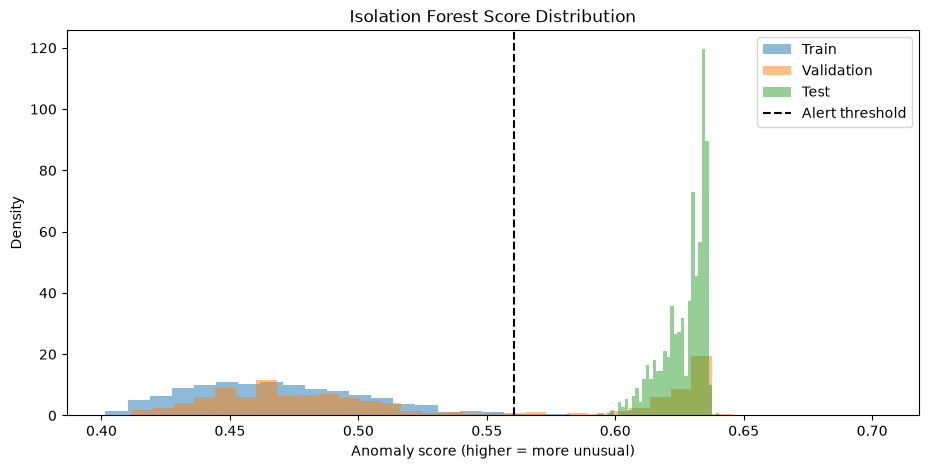

In [8]:

# Day 4: Verify Isolation Forest score drift
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

name = "ec2_cpu_utilization_5f5533"
source = SERIES[name]

df_check, features = load_series(name, source)

n = len(df_check)
train = df_check.iloc[:int(n * 0.60)]
val = df_check.iloc[int(n * 0.60):int(n * 0.80)]
test = df_check.iloc[int(n * 0.80):]

saved = models[name]
scaler = saved["scaler"]
model = saved["model"]
threshold = saved["threshold"]

def anomaly_scores(frame):
    X = scaler.transform(frame[features])
    return -model.score_samples(X)

train_scores = anomaly_scores(train)
val_scores = anomaly_scores(val)
test_scores = anomaly_scores(test)

print("Alert threshold:", round(threshold, 6))

for label, scores in [
    ("Train", train_scores),
    ("Validation", val_scores),
    ("Test", test_scores)
]:
    print(
        label,
        "median:", round(np.median(scores), 6),
        "alert rate:",
        round(100 * np.mean(scores > threshold), 2),
        "%"
    )

plt.figure(figsize=(11, 5))

plt.hist(train_scores, bins=35, alpha=0.5,
         label="Train", density=True)
plt.hist(val_scores, bins=35, alpha=0.5,
         label="Validation", density=True)
plt.hist(test_scores, bins=35, alpha=0.5,
         label="Test", density=True)

plt.axvline(threshold, color="black",
            linestyle="--", label="Alert threshold")

plt.title("Isolation Forest Score Distribution")
plt.xlabel("Anomaly score (higher = more unusual)")
plt.ylabel("Density")
plt.legend()
plt.show()
